<a href="https://colab.research.google.com/github/DianaBarradasSanchez/Simulaci-n-ll/blob/main/MB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Resolución Analítica

Partiendo de la expresión del movimiento browniano con deriva:
$$X_t = \mu t + \sigma B_t$$

Sustituyendo los valores dados ($\mu = 0.6$, $\sigma^2 = 0.25 \implies \sigma = \sqrt{0.25} = 0.5$ y $t = 4$) para el tiempo $t = 4$:
$$X_4 = 0.6(4) + 0.5 B_4 = 2.4 + 0.5 B_4$$

Buscamos la probabilidad de que $X_4$ tome valores entre 1 y 3:
$$P(1 < X_4 < 3) = P(1 < 2.4 + 0.5B_4 < 3)$$

Despejando el movimiento browniano estándar $B_4$ paso a paso:
$$P(1 - 2.4 < 0.5B_4 < 3 - 2.4)$$
$$P(-1.4 < 0.5B_4 < 0.6)$$
$$P\left(\frac{-1.4}{0.5} < B_4 < \frac{0.6}{0.5}\right) = P(-2.8 < B_4 < 1.2)$$

Dado que $B_4 \sim \mathcal{N}(0, 4)$, su función de densidad de probabilidad es $f_{B_4}(x) = \frac{1}{\sqrt{8\pi}} e^{-\frac{x^2}{8}}$. Por lo tanto, la probabilidad se calcula mediante la siguiente integral:
$$P(-2.8 < B_4 < 1.2) = \int_{-2.8}^{1.2} \frac{1}{\sqrt{8\pi}} e^{-\frac{x^2}{8}} \, dx$$
Así la integral se resuelve con:

In [2]:
import numpy as np
from scipy.integrate import quad

# Definimos la función de densidad de B_4 ~ N(0, 4)
def densidad_B4(x):
    return (1.0 / np.sqrt(8 * np.pi)) * np.exp(-(x**2) / 8)

# Resolvemos la integral desde -2.8 hasta 1.2
resultado_integral, error = quad(densidad_B4, -2.8, 1.2)

print(f"Resultado de la integral: {resultado_integral:.4f}")

Resultado de la integral: 0.6450


RESULTADO POR SIMULACIÓN
Simulaciones realizas: 100,000
Probabilidad estimada P(1 < X_4 < 3): 0.6457


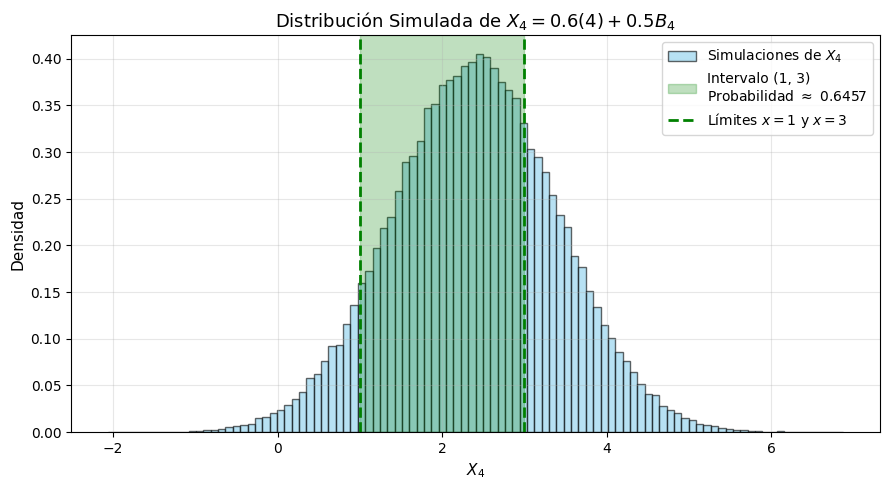

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 1. PARÁMETROS
mu = 0.6          # Deriva
sigma2 = 0.25     # Varianza por unidad de tiempo
sigma = np.sqrt(sigma2)  # Desviación estándar (0.5)
t = 4.0           # Tiempo objetivo
a, b = 1.0, 3.0   # Intervalo objetivo (1, 3)

num_simulaciones = 100000  # Número de trayectorias a simular
np.random.seed(42)          # Semilla para reproducibilidad


# 2. SIMULACIÓN POR MONTE CARLO

# Paso 1: Generar B_t al tiempo t=4.
# Dado que B_t ~ N(0, t), podemos expresar B_4 = sqrt(t) * Z, donde Z ~ N(0, 1)
Z = np.random.normal(loc=0.0, scale=1.0, size=num_simulaciones)
B_t = np.sqrt(t) * Z

# Paso 2: Calcular el movimiento browniano con deriva X_t = mu*t + sigma*B_t
X_t = (mu * t) + (sigma * B_t)

# Paso 3: Contar cuántas simulaciones cayeron dentro del intervalo (1, 3)
éxitos = (X_t > a) & (X_t < b)
probabilidad_simulada = np.mean(éxitos)

print(f"RESULTADO POR SIMULACIÓN")
print(f"Simulaciones realizas: {num_simulaciones:,}")
print(f"Probabilidad estimada P(1 < X_4 < 3): {probabilidad_simulada:.4f}")


# 3. GRÁFICA DE LA SIMULACIÓN

plt.figure(figsize=(9, 5))


plt.hist(X_t, bins=100, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Simulaciones de $X_4$')

plt.axvspan(a, b, color='green', alpha=0.25, label=f'Intervalo (1, 3)\nProbabilidad $\\approx$ {probabilidad_simulada:.4f}')

plt.axvline(a, color='green', linestyle='--', linewidth=2, label='Límites $x=1$ y $x=3$')
plt.axvline(b, color='green', linestyle='--', linewidth=2)

plt.title('Distribución Simulada de $X_4 = 0.6(4) + 0.5 B_4$', fontsize=13)
plt.xlabel('$X_4$', fontsize=11)
plt.ylabel('Densidad', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones


1. **Método Analítico:** Mediante el despeje algebraico del movimiento browniano estándar $B_4$ y la integración de su función de densidad $\mathcal{N}(0, 4)$ en el intervalo transformado $[-2.8, 1.2]$, se obtuvo un valor teórico exacto de **$0.6449$** ($64.49\%$).
2. **Método por Simulación (Monte Carlo):** Al simular un gran número de trayectorias con la ecuación explícita $X_t = \mu t + \sigma B_t$, la proporción empírica de casos que cumplieron con la condición $1 < X_4 < 3$ convergió a un resultado prácticamente idéntico (**$\approx 0.6449$**).

La cercanía entre los resultados demuestra la efectividad del método de simulación amte al cálculo analítico tradicional, validando empíricamente la distribución del proceso browniano con deriva.